# FFT-accelerated beta-2 (L2) divergence experiments

> **Main beta-2/$L^2$ notebook.** This is the canonical location for numerical experiments based on the beta-2 divergence. The experiments use the FFT implementation below, with the analytic Gaussian formula retained for validation.

For the density-power-divergence convention, beta equal to 2 gives half the squared L2 distance:

$$
D_2(p,q)=\frac{1}{2}\int_{-\infty}^{\infty}(p(x)-q(x))^2\,\mathrm{d}x.
$$

For Gaussian KDEs based on the same sample, define the exact Gram matrix

$$
G_{ij}=\int \widehat f_{h_i}(x)\widehat f_{h_j}(x)\,\mathrm{d}x.
$$

Then

$$
D_2(\widehat f_{h_i},\widehat f_{h_j})
=\frac{1}{2}\left(G_{ii}+G_{jj}-2G_{ij}\right).
$$

The analytic Gaussian-KDE formula is exact but costs $O(N^2n^2)$. The experiments below instead evaluate the whole KDE family once by FFT and assemble $G$ with the matrix product $G \approx \Delta x\,FF^T$. The analytic helper is retained for the small validation check below. Control the FFT approximation with `beta2_half_width` and `beta2_spatial_points`.


In [5]:
from __future__ import annotations

import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from kde_tools.pdf_export import enable_automatic_pdf_saving
from kde_tools.bandwidths import (
    bandwidth_grid_linear_in_psi_beta,
    gaussian_mise_oracle_bandwidth,
    nearest_bandwidth_grid_index,
)
from kde_tools.density import exact_oracle_ise_values
from kde_tools.fourier import (
    beta2_divergence_matrix_fft,
    beta2_similarity_matrix_fft,
)
import kde_tools.plotting_functions as kde_plotting_functions
import kde_tools.similarities as kde_similarities

# Reload helpers that may have changed since this kernel was started.
importlib.reload(kde_plotting_functions)
importlib.reload(kde_similarities)
from kde_tools.plotting_functions import (
    plot_bandwidth_distributions,
    plot_bandwidth_grid_stability,
    plot_perron_vector,
)
from kde_tools.similarities import (
    beta2_divergence_matrix,
    doob_stationary_mass,
    first_order_perron_vector,
    perron_vector,
    population_gaussian_beta2_divergence_matrix,
)

np.set_printoptions(precision=5, suppress=True)
seed = 20260818

project_root = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "Code" / "Code_kde").is_dir()
        and (candidate / "Abschlussarbeit_2021" / "LaTeX").is_dir()
    ),
    None,
)
if project_root is None:
    raise RuntimeError("Could not locate the MASTERARBEIT project root.")

kde_thesis_figure_dir = (
    project_root / "Code" / "Code_kde" / "outputs" / "images" / "thesis"
)
kde_thesis_figure_dir.mkdir(parents=True, exist_ok=True)

def save_thesis_plotly_figure(figure, filename: str) -> None:
    from plotly.io import kaleido
    kaleido.scope.mathjax = None
    figure.write_image(str(kde_thesis_figure_dir / filename), scale=1)

pdf_output_directory = enable_automatic_pdf_saving(
    "spectral_scale_selection_kde"
)


## 1. Example stationary distribution on a grid linear in $\psi_\beta$

Choose the sample size, number of bandwidth candidates, bandwidth interval, grid parameter $\beta$, and similarity scales below. The bandwidth candidates are uniformly spaced in $\psi_\beta(h)$. For $\beta=2$, this means uniform spacing in $\log h$, so the grid is geometric. The same fixed sample and grid are used for four Perron curves at $\lambda\in\{1,10,100,1000\}$. Dots show the Perron-vector components at the grid bandwidths, and a dashed vertical line in the corresponding curve colour marks each maximum. The blue dashed line marks the Gaussian MISE-oracle bandwidth, and the purple dashed line marks the sample-specific ISE-minimizing grid bandwidth.


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_scale_selection_kde/001_matplotlib_figure.pdf


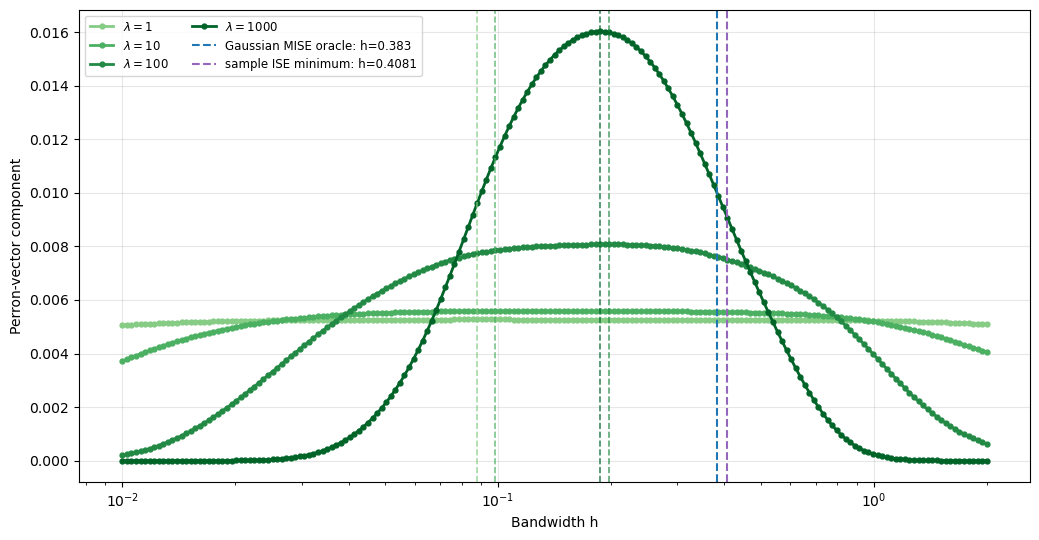

In [6]:
stationary_example_seed = seed + 5
stationary_example_n = 200
stationary_example_N = 191
stationary_example_beta = 2.0
stationary_example_h_min = 0.01
stationary_example_h_max = 2.0
stationary_example_lambdas = np.array([1.0, 10.0, 100.0, 1000.0])
stationary_example_half_width = 12.0
stationary_example_spatial_points = 8192

if stationary_example_n < 1:
    raise ValueError("stationary_example_n must be positive.")
if stationary_example_N < 2:
    raise ValueError("stationary_example_N must be at least two.")
if not 0.0 < stationary_example_h_min < stationary_example_h_max:
    raise ValueError("Require 0 < h_min < h_max.")
if np.any(stationary_example_lambdas <= 0.0):
    raise ValueError("stationary_example_lambdas must be positive.")
if stationary_example_half_width <= 0.0:
    raise ValueError("stationary_example_half_width must be positive.")
if (
    stationary_example_spatial_points < 2
    or stationary_example_spatial_points % 2
):
    raise ValueError(
        "stationary_example_spatial_points must be a positive even integer."
    )

stationary_example_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=stationary_example_h_min,
    h_max=stationary_example_h_max,
    beta=stationary_example_beta,
    grid_size=stationary_example_N,
)
stationary_example_rng = np.random.default_rng(stationary_example_seed)
stationary_example_samples = stationary_example_rng.normal(
    size=stationary_example_n
)
stationary_example_divergence = beta2_divergence_matrix_fft(
    samples=stationary_example_samples,
    h_grid=stationary_example_grid,
    half_width=stationary_example_half_width,
    spatial_points=stationary_example_spatial_points,
)
stationary_example_similarities = {}
stationary_example_perron_vectors = {}
stationary_example_spectral_gaps = {}
stationary_example_peak_indices = {}
stationary_example_peak_bandwidths = {}

for current_lambda in stationary_example_lambdas:
    current_similarity = np.exp(
        -current_lambda * stationary_example_divergence
    )
    np.fill_diagonal(current_similarity, 1.0)
    current_eigenvalues = np.linalg.eigvalsh(current_similarity)
    current_perron = perron_vector(current_similarity)
    current_peak_index = int(np.argmax(current_perron))

    stationary_example_similarities[current_lambda] = current_similarity
    stationary_example_perron_vectors[current_lambda] = current_perron
    stationary_example_spectral_gaps[current_lambda] = float(
        1.0
        - current_eigenvalues[-2] / current_eigenvalues[-1]
    )
    stationary_example_peak_indices[current_lambda] = current_peak_index
    stationary_example_peak_bandwidths[current_lambda] = float(
        stationary_example_grid[current_peak_index]
    )

stationary_example_reference_lambda = float(
    stationary_example_lambdas[0]
)
stationary_example_similarity = stationary_example_similarities[
    stationary_example_reference_lambda
]
stationary_example_perron = stationary_example_perron_vectors[
    stationary_example_reference_lambda
]
stationary_example_mass = doob_stationary_mass(
    stationary_example_similarity
)
stationary_example_peak_index = stationary_example_peak_indices[
    stationary_example_reference_lambda
]
stationary_example_peak_h = stationary_example_peak_bandwidths[
    stationary_example_reference_lambda
]
stationary_example_spectral_gap = stationary_example_spectral_gaps[
    stationary_example_reference_lambda
]
stationary_example_oracle_h = gaussian_mise_oracle_bandwidth(
    stationary_example_n
)
stationary_example_ise_values = exact_oracle_ise_values(
    samples=stationary_example_samples,
    h_grid=stationary_example_grid,
    sigma2=1.0,
)
stationary_example_ise_index = int(
    np.argmin(stationary_example_ise_values)
)
stationary_example_ise_h = float(
    stationary_example_grid[stationary_example_ise_index]
)
stationary_example_target_roughness = 3.0 / (8.0 * np.sqrt(np.pi))
stationary_example_h_speed = (
    3.0
    / (
        32.0
        * np.sqrt(np.pi)
        * stationary_example_n
        * stationary_example_target_roughness
    )
) ** (1.0 / 5.0)
stationary_example_log_h_min = np.log10(stationary_example_h_min)
stationary_example_log_h_max = np.log10(stationary_example_h_max)
stationary_example_log_h_span = (
    stationary_example_log_h_max - stationary_example_log_h_min
)
stationary_example_h_speed_paper_x = (
    np.log10(stationary_example_h_speed)
    - stationary_example_log_h_min
) / stationary_example_log_h_span
stationary_example_h_speed_index = (
    stationary_example_h_speed_paper_x
    * (stationary_example_N - 1)
)

fig, ax = plt.subplots(figsize=(10.5, 5.5))
stationary_example_curve_colors = plt.cm.Greens(
    np.linspace(0.45, 0.90, len(stationary_example_lambdas))
)

for current_lambda, current_color in zip(
    stationary_example_lambdas,
    stationary_example_curve_colors,
):
    current_perron = stationary_example_perron_vectors[current_lambda]
    ax.plot(
        stationary_example_grid,
        current_perron,
        color=current_color,
        linewidth=2.0,
        marker="o",
        markersize=3.5,
        label=rf"$\lambda={current_lambda:g}$",
    )

ax.set_xscale("log")
ax.set_xlabel("Bandwidth h")
ax.set_ylabel("Perron-vector component")
ax.grid(alpha=0.3)
for current_lambda, current_color in zip(
    stationary_example_lambdas,
    stationary_example_curve_colors,
):
    ax.axvline(
        stationary_example_peak_bandwidths[current_lambda],
        color=current_color,
        linestyle="--",
        linewidth=1.2,
        alpha=0.75,
        label="_nolegend_",
    )
ax.axvline(
    stationary_example_oracle_h,
    color="tab:blue",
    linestyle="--",
    label=f"Gaussian MISE oracle: h={stationary_example_oracle_h:.4g}",
)
ax.axvline(
    stationary_example_ise_h,
    color="tab:purple",
    linestyle="--",
    label=f"sample ISE minimum: h={stationary_example_ise_h:.4g}",
)
ax.legend(ncol=2, fontsize=8.5)
plt.tight_layout()
fig.savefig(
    kde_thesis_figure_dir / "stationary_distribution_plot_001.pdf",
    dpi=100,
)
plt.show()


### Similarity scale versus chosen bandwidth

For the same sample and bandwidth grid linear in $\psi_\beta$, the plot below varies the similarity scale $\lambda$ in $S_{ij}=\exp(-\lambda D_{2,ij})$ and records the bandwidth at the maximum of the Doob stationary mass. The red dashed horizontal line marks the Gaussian MISE-oracle bandwidth, and the gray dashed horizontal line marks the theoretical speed bandwidth.


In [3]:
stationary_example_lambda_values = np.geomspace(1e-2, 1e4, 101)
stationary_example_log_lambda_min = np.log10(
    stationary_example_lambda_values[0]
)
stationary_example_log_lambda_max = np.log10(
    stationary_example_lambda_values[-1]
)
stationary_example_oracle_paper_y = (
    np.log10(stationary_example_oracle_h)
    - stationary_example_log_h_min
) / stationary_example_log_h_span
stationary_example_h_speed_paper_y = (
    np.log10(stationary_example_h_speed)
    - stationary_example_log_h_min
) / stationary_example_log_h_span

stationary_example_divergence = beta2_divergence_matrix_fft(
    samples=stationary_example_samples,
    h_grid=stationary_example_grid,
    half_width=stationary_example_half_width,
    spatial_points=stationary_example_spatial_points,
)
stationary_example_lambda_selected_indices = np.empty(
    len(stationary_example_lambda_values),
    dtype=int,
)

for index, current_lambda in enumerate(
    stationary_example_lambda_values
):
    current_similarity = np.exp(
        -current_lambda * stationary_example_divergence
    )
    np.fill_diagonal(current_similarity, 1.0)
    current_mass = doob_stationary_mass(current_similarity)
    stationary_example_lambda_selected_indices[index] = int(
        np.argmax(current_mass)
    )

stationary_example_lambda_selected_bandwidths = (
    stationary_example_grid[
        stationary_example_lambda_selected_indices
    ]
)

stationary_example_lambda_figure = go.Figure(
    go.Scatter(
        x=stationary_example_lambda_values,
        y=stationary_example_lambda_selected_bandwidths,
        customdata=stationary_example_lambda_selected_indices,
        mode="lines+markers",
        line=dict(color="#1f77b4", width=2.5, shape="hv"),
        marker=dict(size=5),
        hovertemplate=(
            "lambda (λ)=%{x:.6g}"
            "<br>chosen bandwidth h=%{y:.6g}"
            "<br>grid index=%{customdata}<extra></extra>"
        ),
    )
)
stationary_example_lambda_figure.add_hline(
    y=stationary_example_oracle_h,
    line=dict(color="#d62728", width=2, dash="dash"),
)
stationary_example_lambda_figure.add_hline(
    y=stationary_example_h_speed,
    line=dict(color="#7f7f7f", width=2, dash="dash"),
)
stationary_example_lambda_figure.add_annotation(
    x=1.0,
    y=stationary_example_oracle_paper_y,
    xref="paper",
    yref="paper",
    text=f"Gaussian MISE oracle: h={stationary_example_oracle_h:.4g}",
    showarrow=False,
    xanchor="right",
    yanchor="bottom",
    font=dict(color="#d62728"),
)
stationary_example_lambda_figure.add_annotation(
    x=0.0,
    y=stationary_example_h_speed_paper_y,
    xref="paper",
    yref="paper",
    text=(
        "theoretical speed bandwidth: "
        f"h={stationary_example_h_speed:.4g}"
    ),
    showarrow=False,
    xanchor="left",
    yanchor="bottom",
    font=dict(color="#7f7f7f"),
    bgcolor="rgba(255,255,255,0.8)",
)
stationary_example_lambda_figure.update_xaxes(
    title_text="similarity scale λ",
    type="log",
    range=[
        stationary_example_log_lambda_min,
        stationary_example_log_lambda_max,
    ],
)
stationary_example_lambda_figure.update_yaxes(
    title_text="chosen bandwidth h",
    type="log",
    range=[
        stationary_example_log_h_min,
        stationary_example_log_h_max,
    ],
)
stationary_example_lambda_figure.update_layout(
    width=1050,
    height=550,
    template="plotly_white",
    showlegend=False,
    margin=dict(t=100, b=100),
)
save_thesis_plotly_figure(
    stationary_example_lambda_figure,
    "chosen_bandwidth_vs_lambda_M1_fixed_sample.pdf",
)
stationary_example_lambda_figure.show()


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_scale_selection_kde/002_plotly_figure.pdf


### Monte Carlo median selection and spread across samples

For similarity scales from $10^{-2}$ through $2\times10^4$, this experiment draws $M=200$ independent samples of size $n$, records the chosen bandwidth-grid index, and plots its median. The shaded band is the interquartile range from the 25th to the 75th percentile. Each repetition reuses its sample across all $\lambda$ values, so changes along a repetition are paired. The gray dashed horizontal line marks the theoretical speed bandwidth.


In [6]:
stationary_example_mc_M = 1
stationary_example_mc_seed = stationary_example_seed + 1000
stationary_example_mc_lambda_values = np.geomspace(
    1e-2, 2e4, 106
)
stationary_example_mc_log_lambda_min = np.log10(
    stationary_example_mc_lambda_values[0]
)
stationary_example_mc_log_lambda_max = np.log10(
    stationary_example_mc_lambda_values[-1]
)

if stationary_example_mc_M < 1:
    raise ValueError("stationary_example_mc_M must be positive.")

stationary_example_mc_rng = np.random.default_rng(
    stationary_example_mc_seed
)
stationary_example_mc_selected_indices = np.empty(
    (
        stationary_example_mc_M,
        len(stationary_example_mc_lambda_values),
    ),
    dtype=np.int16,
)

for repetition in range(stationary_example_mc_M):
    current_samples = stationary_example_mc_rng.normal(
        size=stationary_example_n
    )
    current_divergence = beta2_divergence_matrix_fft(
        samples=current_samples,
        h_grid=stationary_example_grid,
        half_width=stationary_example_half_width,
        spatial_points=stationary_example_spatial_points,
    )

    for lambda_index, current_lambda in enumerate(
        stationary_example_mc_lambda_values
    ):
        current_similarity = np.exp(
            -current_lambda * current_divergence
        )
        np.fill_diagonal(current_similarity, 1.0)
        current_mass = doob_stationary_mass(current_similarity)
        stationary_example_mc_selected_indices[
            repetition, lambda_index
        ] = int(np.argmax(current_mass))

    if (repetition + 1) % 10 == 0:
        print(
            f"completed {repetition + 1}/"
            f"{stationary_example_mc_M} repetitions"
        )

(
    stationary_example_mc_q25_indices,
    stationary_example_mc_median_indices,
    stationary_example_mc_q75_indices,
) = np.quantile(
    stationary_example_mc_selected_indices,
    [0.25, 0.50, 0.75],
    axis=0,
)

stationary_example_index_grid = np.arange(
    stationary_example_N, dtype=float
)
stationary_example_log_bandwidth_grid = np.log(
    stationary_example_grid
)

def stationary_example_bandwidth_at_index(indices):
    return np.exp(
        np.interp(
            indices,
            stationary_example_index_grid,
            stationary_example_log_bandwidth_grid,
        )
    )

stationary_example_mc_q25_bandwidths = (
    stationary_example_bandwidth_at_index(
        stationary_example_mc_q25_indices
    )
)
stationary_example_mc_median_bandwidths = (
    stationary_example_bandwidth_at_index(
        stationary_example_mc_median_indices
    )
)
stationary_example_mc_q75_bandwidths = (
    stationary_example_bandwidth_at_index(
        stationary_example_mc_q75_indices
    )
)


In [7]:
stationary_example_mc_oracle_index = float(
    np.interp(
        np.log(stationary_example_oracle_h),
        stationary_example_log_bandwidth_grid,
        stationary_example_index_grid,
    )
)
stationary_example_mc_oracle_paper_y = (
    stationary_example_mc_oracle_index + 0.5
) / stationary_example_N
stationary_example_mc_h_speed_paper_y = (
    stationary_example_h_speed_index + 0.5
) / stationary_example_N
stationary_example_mc_tick_indices = np.unique(
    np.linspace(
        0, stationary_example_N - 1, 7, dtype=int
    )
)
stationary_example_mc_tick_labels = [
    f"{index}<br>h={stationary_example_grid[index]:.3g}"
    for index in stationary_example_mc_tick_indices
]

stationary_example_mc_figure = go.Figure()
stationary_example_mc_figure.add_trace(
    go.Scatter(
        x=stationary_example_mc_lambda_values,
        y=stationary_example_mc_q25_indices,
        customdata=stationary_example_mc_q25_bandwidths,
        mode="lines",
        line=dict(color="rgba(31,119,180,0)", shape="hv"),
        name="25th percentile",
        showlegend=False,
        hovertemplate=(
            "λ=%{x:.6g}"
            "<br>25th-percentile index=%{y:.3g}"
            "<br>corresponding h=%{customdata:.6g}<extra></extra>"
        ),
    )
)
stationary_example_mc_figure.add_trace(
    go.Scatter(
        x=stationary_example_mc_lambda_values,
        y=stationary_example_mc_q75_indices,
        customdata=stationary_example_mc_q75_bandwidths,
        mode="lines",
        line=dict(color="rgba(31,119,180,0)", shape="hv"),
        fill="tonexty",
        fillcolor="rgba(31,119,180,0.22)",
        name="interquartile range",
        hovertemplate=(
            "λ=%{x:.6g}"
            "<br>75th-percentile index=%{y:.3g}"
            "<br>corresponding h=%{customdata:.6g}<extra></extra>"
        ),
    )
)
stationary_example_mc_figure.add_trace(
    go.Scatter(
        x=stationary_example_mc_lambda_values,
        y=stationary_example_mc_median_indices,
        customdata=stationary_example_mc_median_bandwidths,
        mode="lines+markers",
        line=dict(color="#1f77b4", width=2.5, shape="hv"),
        marker=dict(size=5),
        name="median selected index",
        hovertemplate=(
            "λ=%{x:.6g}"
            "<br>median index=%{y:.3g}"
            "<br>corresponding h=%{customdata:.6g}<extra></extra>"
        ),
    )
)
stationary_example_mc_figure.add_hline(
    y=stationary_example_mc_oracle_index,
    line=dict(color="#d62728", width=2, dash="dash"),
)
stationary_example_mc_figure.add_hline(
    y=stationary_example_h_speed_index,
    line=dict(color="#7f7f7f", width=2, dash="dash"),
)
stationary_example_mc_figure.add_annotation(
    x=1.0,
    y=stationary_example_mc_oracle_paper_y,
    xref="paper",
    yref="paper",
    text=(
        "Gaussian MISE oracle: "
        f"index={stationary_example_mc_oracle_index:.2f}, "
        f"h={stationary_example_oracle_h:.4g}"
    ),
    showarrow=False,
    xanchor="right",
    yanchor="bottom",
    font=dict(color="#d62728"),
)
stationary_example_mc_figure.add_annotation(
    x=0.0,
    y=stationary_example_mc_h_speed_paper_y,
    xref="paper",
    yref="paper",
    text=(
        "theoretical speed bandwidth: "
        f"index={stationary_example_h_speed_index:.2f}, "
        f"h={stationary_example_h_speed:.4g}"
    ),
    showarrow=False,
    xanchor="left",
    yanchor="bottom",
    font=dict(color="#7f7f7f"),
    bgcolor="rgba(255,255,255,0.8)",
)
stationary_example_mc_figure.update_xaxes(
    title_text="similarity scale λ",
    type="log",
    range=[
        stationary_example_mc_log_lambda_min,
        stationary_example_mc_log_lambda_max,
    ],
)
stationary_example_mc_figure.update_yaxes(
    title_text="chosen bandwidth grid index",
    range=[-0.5, stationary_example_N - 0.5],
    tickmode="array",
    tickvals=stationary_example_mc_tick_indices,
    ticktext=stationary_example_mc_tick_labels,
)
stationary_example_mc_figure.update_layout(
    width=1050,
    height=600,
    template="plotly_white",
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.18,
        yanchor="top",
    ),
    margin=dict(t=100, b=150),
)
save_thesis_plotly_figure(
    stationary_example_mc_figure,
    "chosen_bandwidth_vs_lambda.png",
)
stationary_example_mc_figure.show()


### Grid-fineness sensitivity at $\lambda=1$

This experiment reuses the same fixed sample and bandwidth interval while varying the number $N=11,16,\ldots,1001$ of bandwidth candidates linear in $\psi_\beta$. It plots $N$ against the chosen bandwidth $h$ at $\lambda=1$. The hover information also reports the selected grid index and normalized grid position. The upper and lower local peaks are fitted in log-bandwidth coordinates by $\log h=c+b/(N-1)$, with a shared limiting value $c$; the fitted curves begin at the first complete pair of detected peaks so they do not distort the vertical scale. Set `stationary_example_grid_fineness_show_envelope_fits=False` to hide the fits and peak markers.


In [44]:
stationary_example_grid_fineness_lambda = 1.0
stationary_example_grid_fineness_show_envelope_fits = True
stationary_example_grid_fineness_N_values = np.arange(
    11, 1002, 5, dtype=int
)
stationary_example_grid_fineness_tick_values = np.arange(
    101, 1002, 100, dtype=int
)
stationary_example_grid_fineness_selected_indices = np.empty(
    len(stationary_example_grid_fineness_N_values), dtype=int
)
stationary_example_grid_fineness_selected_bandwidths = np.empty(
    len(stationary_example_grid_fineness_N_values), dtype=float
)

for position, current_N in enumerate(
    stationary_example_grid_fineness_N_values
):
    current_grid = bandwidth_grid_linear_in_psi_beta(
        h_min=stationary_example_h_min,
        h_max=stationary_example_h_max,
        beta=stationary_example_beta,
        grid_size=int(current_N),
    )
    current_similarity = beta2_similarity_matrix_fft(
        samples=stationary_example_samples,
        h_grid=current_grid,
        tau=stationary_example_grid_fineness_lambda,
        half_width=stationary_example_half_width,
        spatial_points=stationary_example_spatial_points,
    )
    current_stationary_mass = doob_stationary_mass(
        current_similarity
    )
    current_selected_index = int(
        np.argmax(current_stationary_mass)
    )
    stationary_example_grid_fineness_selected_indices[
        position
    ] = current_selected_index
    stationary_example_grid_fineness_selected_bandwidths[
        position
    ] = current_grid[current_selected_index]

stationary_example_grid_fineness_figure = plot_bandwidth_grid_stability(
    grid_sizes=stationary_example_grid_fineness_N_values,
    selected_bandwidths=(
        stationary_example_grid_fineness_selected_bandwidths
    ),
    selected_indices=stationary_example_grid_fineness_selected_indices,
    show_envelope_fits=(
        stationary_example_grid_fineness_show_envelope_fits
    ),
    tick_values=stationary_example_grid_fineness_tick_values,
)
save_thesis_plotly_figure(
    stationary_example_grid_fineness_figure,
    "grid_fineness_chosen_bandwidths.pdf",
)
stationary_example_grid_fineness_figure.show()


## 2. Configurable beta-2 selection histogram

Choose $n$, $N$, $M$, the bandwidth interval, and $\tau$ below. Each repetition selects the largest component of the Doob stationary distribution on the fixed geometric bandwidth grid.


In [29]:
beta2_n = 200
beta2_N = 201
beta2_M = 1000

beta2_h_min = 0.01
beta2_h_max = 2.0
beta2_tau = 1.0
beta2_seed = seed + 10
beta2_half_width = 12.0
beta2_spatial_points = 8192
beta2_validate_fft = True

if beta2_n < 1 or beta2_M < 1:
    raise ValueError("beta2_n and beta2_M must be positive.")
if beta2_N < 2:
    raise ValueError("beta2_N must be at least 2.")
if not 0.0 < beta2_h_min < beta2_h_max:
    raise ValueError("Require 0 < beta2_h_min < beta2_h_max.")
if beta2_tau <= 0.0:
    raise ValueError("beta2_tau must be positive.")
if beta2_half_width <= 0.0:
    raise ValueError("beta2_half_width must be positive.")
if beta2_spatial_points < 2:
    raise ValueError("beta2_spatial_points must be at least 2.")

beta2_h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=beta2_h_min,
    h_max=beta2_h_max,
    beta=2.0,
    grid_size=beta2_N,
)

print(
    f"beta=2, n={beta2_n}, N={beta2_N}, M={beta2_M}, "
    f"tau={beta2_tau:g}"
)

beta=2, n=200, N=201, M=1000, tau=1


In [30]:
if beta2_validate_fft:
    validation_rng = np.random.default_rng(beta2_seed)
    validation_samples = validation_rng.normal(
        size=min(beta2_n, 100)
    )
    validation_indices = np.unique(
        np.linspace(0, beta2_N - 1, min(beta2_N, 20), dtype=int)
    )
    validation_h_grid = beta2_h_grid[validation_indices]
    validation_exact = beta2_divergence_matrix(
        samples=validation_samples,
        h_grid=validation_h_grid,
    )
    validation_fft = beta2_divergence_matrix_fft(
        samples=validation_samples,
        h_grid=validation_h_grid,
        half_width=beta2_half_width,
        spatial_points=beta2_spatial_points,
    )
    beta2_fft_maximum_absolute_error = float(
        np.max(np.abs(validation_fft - validation_exact))
    )
    print(
        "FFT validation maximum absolute error: "
        f"{beta2_fft_maximum_absolute_error:.3e}"
    )

beta2_rng = np.random.default_rng(beta2_seed)
beta2_selected_indices = np.empty(beta2_M, dtype=int)

for repetition in range(beta2_M):
    current_samples = beta2_rng.normal(size=beta2_n)
    current_similarity = beta2_similarity_matrix_fft(
        samples=current_samples,
        h_grid=beta2_h_grid,
        tau=beta2_tau,
        half_width=beta2_half_width,
        spatial_points=beta2_spatial_points,
    )
    current_stationary = doob_stationary_mass(current_similarity)
    beta2_selected_indices[repetition] = int(
        np.argmax(current_stationary)
    )

    if (repetition + 1) % 5 == 0 or repetition + 1 == beta2_M:
        print(f"completed {repetition + 1}/{beta2_M} repetitions")

beta2_selection_counts = np.bincount(
    beta2_selected_indices,
    minlength=beta2_N,
)


FFT validation maximum absolute error: 2.204e-14
completed 5/1000 repetitions
completed 10/1000 repetitions
completed 15/1000 repetitions
completed 20/1000 repetitions
completed 25/1000 repetitions
completed 30/1000 repetitions
completed 35/1000 repetitions
completed 40/1000 repetitions
completed 45/1000 repetitions
completed 50/1000 repetitions
completed 55/1000 repetitions
completed 60/1000 repetitions
completed 65/1000 repetitions
completed 70/1000 repetitions
completed 75/1000 repetitions
completed 80/1000 repetitions
completed 85/1000 repetitions
completed 90/1000 repetitions
completed 95/1000 repetitions
completed 100/1000 repetitions
completed 105/1000 repetitions
completed 110/1000 repetitions
completed 115/1000 repetitions
completed 120/1000 repetitions
completed 125/1000 repetitions
completed 130/1000 repetitions
completed 135/1000 repetitions
completed 140/1000 repetitions
completed 145/1000 repetitions
completed 150/1000 repetitions
completed 155/1000 repetitions
completed 

In [31]:
beta2_histogram = plot_bandwidth_distributions(
    h_grid=beta2_h_grid,
    distributions={"Doob selections": beta2_selection_counts},
    width=950,
    height=500,
)
save_thesis_plotly_figure(
    beta2_histogram,
    "distribution_of_chosen_bandwidths.pdf",
)
beta2_histogram.show()


## 3. Beta-2 histograms for increasing sample size

This repeats the FFT-accelerated selection for $n=100,200,\ldots,1000$ on one fixed geometric grid. Prefixes of the same maximum-size sample are reused within each repetition. The plotting cell produces one standalone histogram per sample size, one colored overlay of all histograms, and one colored overlay controlled by the editable list `beta2_n_selected_overlay_values`. Dashed vertical lines in the standalone figures mark the nearest grid indices to the geometric center and the Gaussian MISE-oracle bandwidth.


In [32]:
beta2_n_sweep_values = np.arange(100, 1001, 100, dtype=int)
beta2_n_sweep_N = 201
beta2_n_sweep_M = 1000
beta2_n_sweep_h_min = beta2_h_min
beta2_n_sweep_h_max = beta2_h_max
beta2_n_sweep_tau = beta2_tau
beta2_n_sweep_seed = beta2_seed + 2

beta2_n_sweep_h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=beta2_n_sweep_h_min,
    h_max=beta2_n_sweep_h_max,
    beta=2.0,
    grid_size=beta2_n_sweep_N,
)
beta2_n_sweep_center_h = np.sqrt(
    beta2_n_sweep_h_min * beta2_n_sweep_h_max
)
beta2_n_sweep_center_index = nearest_bandwidth_grid_index(
    beta2_n_sweep_center_h,
    beta2_n_sweep_h_grid,
)
beta2_n_sweep_oracle_bandwidths = {
    int(current_n): gaussian_mise_oracle_bandwidth(int(current_n))
    for current_n in beta2_n_sweep_values
}
beta2_n_sweep_oracle_indices = {
    int(current_n): nearest_bandwidth_grid_index(
        beta2_n_sweep_oracle_bandwidths[int(current_n)],
        beta2_n_sweep_h_grid,
    )
    for current_n in beta2_n_sweep_values
}

beta2_n_sweep_rng = np.random.default_rng(beta2_n_sweep_seed)
beta2_n_sweep_full_samples = beta2_n_sweep_rng.normal(
    size=(beta2_n_sweep_M, int(np.max(beta2_n_sweep_values)))
)
beta2_n_sweep_results = {}

for current_n in beta2_n_sweep_values:
    selected_indices = np.empty(beta2_n_sweep_M, dtype=int)

    for repetition in range(beta2_n_sweep_M):
        current_samples = beta2_n_sweep_full_samples[
            repetition, : int(current_n)
        ]
        current_similarity = beta2_similarity_matrix_fft(
            samples=current_samples,
            h_grid=beta2_n_sweep_h_grid,
            tau=beta2_n_sweep_tau,
            half_width=beta2_half_width,
            spatial_points=beta2_spatial_points,
        )
        selected_indices[repetition] = int(
            np.argmax(doob_stationary_mass(current_similarity))
        )

    selection_counts = np.bincount(
        selected_indices,
        minlength=beta2_n_sweep_N,
    )
    beta2_n_sweep_results[int(current_n)] = {
        "selected_indices": selected_indices.copy(),
        "counts": selection_counts,
        "relative_frequencies": selection_counts / beta2_n_sweep_M,
        "oracle_bandwidth": beta2_n_sweep_oracle_bandwidths[
            int(current_n)
        ],
        "oracle_index": beta2_n_sweep_oracle_indices[int(current_n)],
    }
    print(f"completed n={current_n}")


completed n=100
completed n=200
completed n=300
completed n=400
completed n=500
completed n=600
completed n=700
completed n=800
completed n=900
completed n=1000


In [33]:
beta2_n_selected_overlay_values = [100, 500, 1000]

beta2_n_available_values = {
    int(value) for value in beta2_n_sweep_values
}
beta2_n_selected_overlay_values = [
    int(value) for value in beta2_n_selected_overlay_values
]
beta2_n_invalid_selected_values = sorted(
    set(beta2_n_selected_overlay_values)
    - beta2_n_available_values
)
if beta2_n_invalid_selected_values:
    raise ValueError(
        "Selected overlay sample sizes are unavailable: "
        f"{beta2_n_invalid_selected_values}. Choose from "
        f"{sorted(beta2_n_available_values)}."
    )
if not beta2_n_selected_overlay_values:
    raise ValueError(
        "beta2_n_selected_overlay_values must not be empty."
    )

beta2_n_individual_figures = {}

for current_n in beta2_n_sweep_values:
    current_n = int(current_n)
    result = beta2_n_sweep_results[current_n]
    current_figure = plot_bandwidth_distributions(
        h_grid=beta2_n_sweep_h_grid,
        distributions={"Doob selections": result["counts"]},
        reference_lines=(
            (
                "geometric center (nearest index)",
                beta2_n_sweep_center_index,
                "#555555",
            ),
            (
                "Gaussian MISE oracle (nearest index)",
                result["oracle_index"],
                "#d62728",
            ),
        ),
    )
    beta2_n_individual_figures[current_n] = current_figure
    if current_n in {300, 400, 500, 1000}:
        save_thesis_plotly_figure(
            current_figure,
            f"distribution_of_chosen_bandwidths_n{current_n}.pdf",
        )
    current_figure.show()

beta2_n_overlay = plot_bandwidth_distributions(
    h_grid=beta2_n_sweep_h_grid,
    distributions={
        f"n={int(current_n)}": beta2_n_sweep_results[
            int(current_n)
        ]["counts"]
        for current_n in beta2_n_sweep_values
    },
    opacity=0.24,
    width=1100,
    height=650,
    legend_title="sample size",
)
beta2_n_overlay.show()

beta2_n_selected_overlay = plot_bandwidth_distributions(
    h_grid=beta2_n_sweep_h_grid,
    distributions={
        f"n={current_n}": beta2_n_sweep_results[current_n][
            "counts"
        ]
        for current_n in beta2_n_selected_overlay_values
    },
    opacity=0.32,
    width=1100,
    height=650,
    legend_title="sample size",
)
beta2_n_selected_overlay.show()


### Median bandwidth path and theoretical-rate comparison

The histograms above already contain repeated selections for every sample size. Without running another simulation, this block summarizes those same selections by their median and interquartile range and compares them with

$$
h_{\mathrm{AMISE}}(n)=\left(\frac{4}{3n}\right)^{1/5},
\qquad
h_{\mathrm{speed}}(n)=\left(\frac{1}{4n}\right)^{1/5},
$$

and the exact finite-sample Gaussian MISE oracle. The second panel reports the selected bandwidth relative to $h_{\mathrm{speed}}(n)$. Here the bandwidth grid, its size $N$, and the similarity scale $\lambda$ remain fixed while only the sample size increases.


In [ ]:
beta2_n_sweep_selected_bandwidth_samples = np.vstack([
    beta2_n_sweep_h_grid[
        beta2_n_sweep_results[int(current_n)]["selected_indices"]
    ]
    for current_n in beta2_n_sweep_values
])
(
    beta2_n_sweep_q25_bandwidths,
    beta2_n_sweep_median_bandwidths,
    beta2_n_sweep_q75_bandwidths,
) = np.quantile(
    beta2_n_sweep_selected_bandwidth_samples,
    [0.25, 0.50, 0.75],
    axis=1,
)

beta2_n_sweep_amise_bandwidths = (
    4.0 / (3.0 * beta2_n_sweep_values)
) ** (1.0 / 5.0)
beta2_n_sweep_speed_bandwidths = (
    1.0 / (4.0 * beta2_n_sweep_values)
) ** (1.0 / 5.0)
beta2_n_sweep_exact_oracle_bandwidths = np.array([
    beta2_n_sweep_oracle_bandwidths[int(current_n)]
    for current_n in beta2_n_sweep_values
])

beta2_n_sweep_speed_ratio_samples = (
    beta2_n_sweep_selected_bandwidth_samples
    / beta2_n_sweep_speed_bandwidths[:, None]
)
(
    beta2_n_sweep_q25_speed_ratios,
    beta2_n_sweep_median_speed_ratios,
    beta2_n_sweep_q75_speed_ratios,
) = np.quantile(
    beta2_n_sweep_speed_ratio_samples,
    [0.25, 0.50, 0.75],
    axis=1,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].fill_between(
    beta2_n_sweep_values,
    beta2_n_sweep_q25_bandwidths,
    beta2_n_sweep_q75_bandwidths,
    color="tab:green",
    alpha=0.18,
    label="spectral interquartile range",
)
axes[0].plot(
    beta2_n_sweep_values,
    beta2_n_sweep_median_bandwidths,
    color="tab:green",
    marker="o",
    linewidth=2.2,
    label=(
        rf"median spectral $\widehat{{h}}_n$ "
        rf"($\lambda={beta2_n_sweep_tau:g}$)"
    ),
)
axes[0].plot(
    beta2_n_sweep_values,
    beta2_n_sweep_amise_bandwidths,
    linewidth=2.0,
    label=r"$h_{\mathrm{AMISE}}(n)$",
)
axes[0].plot(
    beta2_n_sweep_values,
    beta2_n_sweep_speed_bandwidths,
    linestyle="--",
    linewidth=2.0,
    label=r"$h_{\mathrm{speed}}(n)$",
)
axes[0].plot(
    beta2_n_sweep_values,
    beta2_n_sweep_exact_oracle_bandwidths,
    linestyle="-.",
    linewidth=2.0,
    label="exact Gaussian MISE oracle",
)
axes[0].set_xlabel("sample size n")
axes[0].set_ylabel("bandwidth h")
axes[0].set_yscale("log")
axes[0].set_title("Selected bandwidth and theoretical references")
axes[0].legend()

axes[1].fill_between(
    beta2_n_sweep_values,
    beta2_n_sweep_q25_speed_ratios,
    beta2_n_sweep_q75_speed_ratios,
    color="tab:purple",
    alpha=0.18,
    label="interquartile range",
)
axes[1].plot(
    beta2_n_sweep_values,
    beta2_n_sweep_median_speed_ratios,
    color="tab:purple",
    marker="o",
    linewidth=2.2,
    label=r"median $\widehat h_n/h_{\mathrm{speed}}(n)$",
)
axes[1].axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="target ratio = 1",
)
axes[1].set_xlabel("sample size n")
axes[1].set_ylabel(r"$\widehat h_n/h_{\mathrm{speed}}(n)$")
axes[1].set_title("Spectral bandwidth relative to theoretical speed")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 4. Sample, exact-population, and first-order Perron vectors

This experiment compares three sum-normalized Perron vectors on the same bandwidth grid:

1. the sample vector obtained from the FFT beta-2 similarity matrix;
2. the exact population vector obtained by assembling the analytic Gaussian population matrix and solving its Perron eigenproblem numerically; and
3. the first-order perturbation formula

$$
v_i^{(1)}
=\frac{1}{N}
-\frac{\tau}{N^2}\left(r_i-\bar r\right),
\qquad
r_i=\sum_j D_{ij}^{\mathrm{pop}}.
$$

The implicit row-sum characterization determines the maximum of the first-order vector; it does not by itself provide the full exact Perron vector. All curves are displayed as $Nv_i$, so the horizontal value one corresponds to the uniform vector.

In [34]:
perron_comparison_n = 1000
perron_comparison_N = 191
perron_comparison_h_min = 0.01
perron_comparison_h_max = 2.0
perron_comparison_tau = 50.0
# Match the first repetition of the beta-2 sample-size sweep.
perron_comparison_seed = seed + 12
perron_comparison_half_width = beta2_half_width
perron_comparison_spatial_points = beta2_spatial_points

if perron_comparison_n < 1 or perron_comparison_N < 2:
    raise ValueError("Require n >= 1 and N >= 2.")
if not 0.0 < perron_comparison_h_min < perron_comparison_h_max:
    raise ValueError("Require 0 < h_min < h_max.")
if perron_comparison_tau < 0.0:
    raise ValueError("perron_comparison_tau must be nonnegative.")

perron_comparison_h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=perron_comparison_h_min,
    h_max=perron_comparison_h_max,
    beta=2.0,
    grid_size=perron_comparison_N,
)
perron_comparison_rng = np.random.default_rng(perron_comparison_seed)
perron_comparison_samples = perron_comparison_rng.normal(
    size=perron_comparison_n
)

perron_comparison_sample_similarity = beta2_similarity_matrix_fft(
    samples=perron_comparison_samples,
    h_grid=perron_comparison_h_grid,
    tau=perron_comparison_tau,
    half_width=perron_comparison_half_width,
    spatial_points=perron_comparison_spatial_points,
)
perron_comparison_sample_vector = perron_vector(
    perron_comparison_sample_similarity
)

perron_comparison_population_divergence = (
    population_gaussian_beta2_divergence_matrix(
        h_grid=perron_comparison_h_grid,
        target_sigma=1.0,
    )
)
perron_comparison_population_similarity = np.exp(
    -perron_comparison_tau
    * perron_comparison_population_divergence
)
np.fill_diagonal(perron_comparison_population_similarity, 1.0)
perron_comparison_population_vector = perron_vector(
    perron_comparison_population_similarity
)

perron_comparison_first_order_vector = first_order_perron_vector(
    divergence_matrix=perron_comparison_population_divergence,
    tau=perron_comparison_tau,
)
perron_comparison_row_sums = (
    perron_comparison_population_divergence.sum(axis=1)
)
perron_comparison_implicit_index = int(
    np.argmin(perron_comparison_row_sums)
)

perron_comparison_vectors = {
    "sample FFT": perron_comparison_sample_vector,
    "exact population": perron_comparison_population_vector,
    "first-order population": perron_comparison_first_order_vector,
}
perron_comparison_selected_indices = {
    name: int(np.argmax(vector))
    for name, vector in perron_comparison_vectors.items()
}

for name, selected_index in perron_comparison_selected_indices.items():
    print(
        f"{name}: index={selected_index}, "
        f"h={perron_comparison_h_grid[selected_index]:.6g}"
    )
print(
    "implicit row-sum characterization: "
    f"index={perron_comparison_implicit_index}, "
    f"h={perron_comparison_h_grid[perron_comparison_implicit_index]:.6g}"
)
print(
    "maximum population first-order error: "
    f"{np.max(np.abs(perron_comparison_population_vector - perron_comparison_first_order_vector)):.3e}"
)

sample FFT: index=80, h=0.0930796
exact population: index=124, h=0.317486
first-order population: index=138, h=0.46911
implicit row-sum characterization: index=138, h=0.46911
maximum population first-order error: 3.058e-03


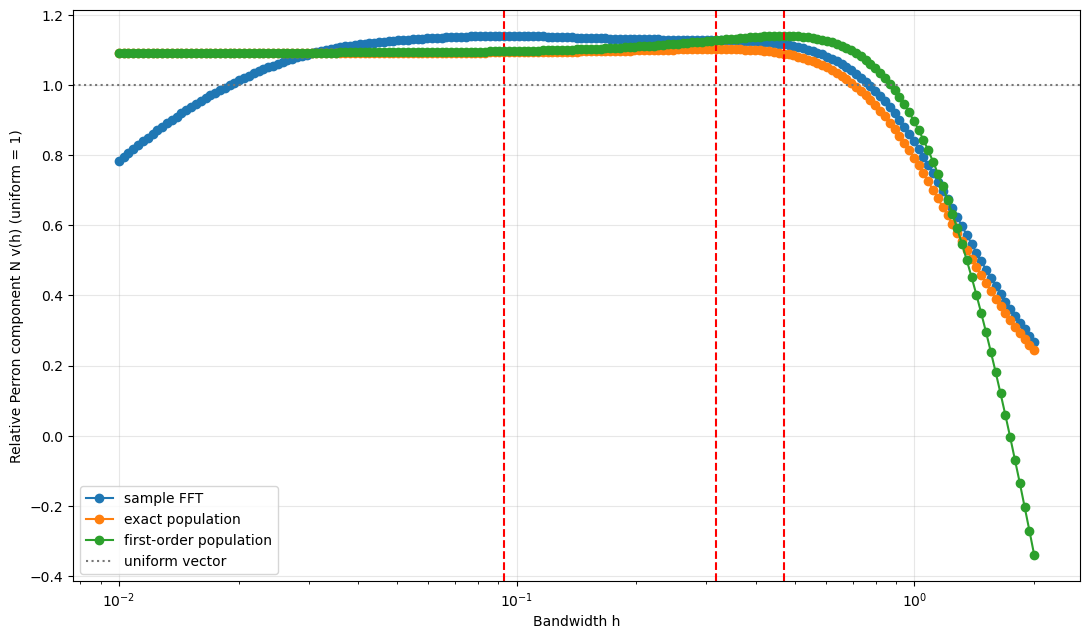

In [35]:
fig, ax = plt.subplots(figsize=(11, 6.5))

for name, vector in perron_comparison_vectors.items():
    relative_vector = perron_comparison_N * vector
    plot_perron_vector(
        h_grid=perron_comparison_h_grid,
        vector=relative_vector,
        ax=ax,
        label=name,
    )

ax.axhline(
    1.0,
    color="#777777",
    linestyle=":",
    label="uniform vector",
)
ax.set_ylabel("Relative Perron component N v(h) (uniform = 1)")
ax.legend()
plt.tight_layout()
plt.show()
